# 03 — Baselines and AutoML v0.1 (grid search)
**Owner:** Sharan Raj JANAKIRAMAN (M3)

**Goal (Week 3 + LAB 6 Part II):** tune the standard course models with grid search, compare them with the baselines using the same folds and the same metric, and look at their errors and limits.

**How the numbers were produced** (code in `src/models/`):
- `python -m src.models.run_baselines` → `results/baseline_train.csv`
- `python -m src.models.automl search` → grid search on a subsample of whole accidents → `results/automl_v01_search.csv`, `automl_v01_best_params.json`

All scores come from the **training years 2019–2023** with **5 folds grouped by accident**. The test years 2024–2025 are not used here.

**LAB 6 traps avoided:** PR-AUC instead of accuracy; 5 folds instead of 2; folds grouped by accident instead of a random split; preprocessing inside the Pipeline; no model or threshold chosen on the test years; grids that include simple models to see the bias–variance trade-off.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RESULTS_DIR, FIGURES_DIR, PROCESSED_DIR
from src.features.build_features import add_features
from src.features.split import get_splits

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
search = pd.read_csv(RESULTS_DIR / "automl_v01_search.csv")
best = json.loads((RESULTS_DIR / "automl_v01_best_params.json").read_text())
base = pd.read_csv(RESULTS_DIR / "baseline_train.csv", index_col=0)

## 1. Grid search results (subsample of whole accidents)
Best setting of each model, its mean cross-validated PR-AUC (± standard deviation over the 5 folds) and the PR-AUC on the training folds. A large gap between train and validation = overfitting (high variance).

In [2]:
tab = pd.DataFrame([{"model": m, "best settings": {k.replace("model__", ""): v for k, v in b["params"].items()},
                     "CV PR-AUC": round(b["cv_pr_auc_mean"], 4), "± std": round(b["cv_pr_auc_std"], 4),
                     "train PR-AUC": round(b["train_pr_auc_mean"], 4), "people": b["subsample_people"],
                     "search time (s)": b["search_time_s"]} for m, b in best.items()]).sort_values("CV PR-AUC", ascending=False)
display(tab)
print("Settings tested:", search.groupby("model").size().to_dict())

,model,best settings,CV PR-AUC,± std,train PR-AUC,people,search time (s)
0,Logistic regression,{'C': 0.1},0.5897,0.0067,0.5988,99999,285
4,SVM,{'C': 1},0.5805,0.0123,0.8004,10000,90
2,Random forest,"{'max_depth': None, 'min_samples_leaf': 1}",0.5797,0.0111,0.9999,29999,126
3,k-nearest neighbours,"{'n_neighbors': 25, 'weights': 'distance'}",0.5396,0.0072,1.0000,19998,348
1,Decision tree,"{'max_depth': 16, 'min_samples_leaf': 100}",0.5304,0.0104,0.5723,29999,50


Settings tested: {'Decision tree': 8, 'Logistic regression': 4, 'Random forest': 4, 'SVM': 2, 'k-nearest neighbours': 6}


## 2. Bias–variance: decision tree depth
LAB 6 Exercise 1 asks what happens with `max_depth=None` and `min_samples_leaf=1`. Here are our real numbers.

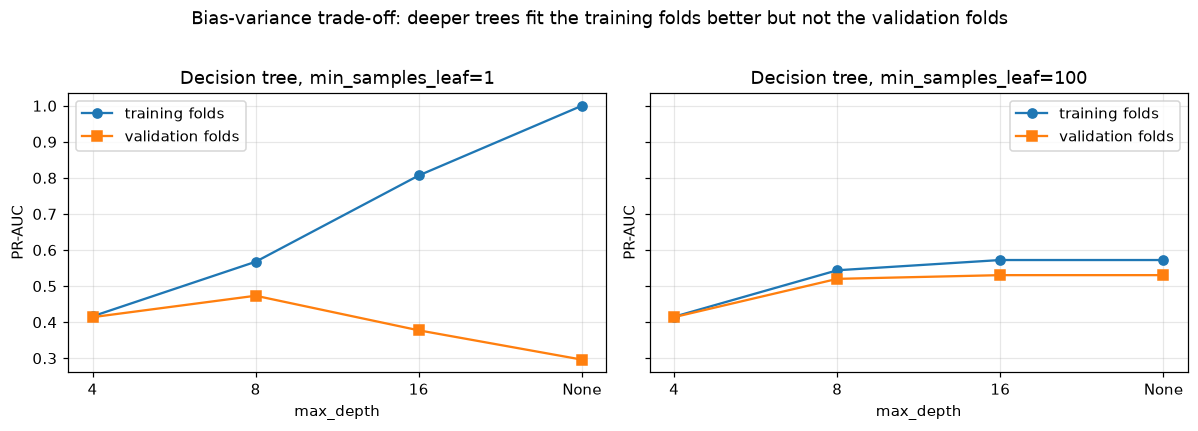

leaf,1,100
max_depth,,
4,0.4139,0.4140
8,0.4733,0.5201
16,0.3774,0.5304
None,0.2962,0.5304


In [3]:
dt = search[search.model == "Decision tree"].copy()
dt["params"] = dt.params.apply(json.loads)
dt["max_depth"] = dt.params.apply(lambda p: "None" if p["max_depth"] is None else str(p["max_depth"]))
dt["leaf"] = dt.params.apply(lambda p: p["min_samples_leaf"])
g = dt
order = ["4", "8", "16", "None"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, leaf in zip(axes, [1, 100]):
    s = g[g.leaf == leaf].set_index("max_depth").loc[order]
    ax.plot(order, s.train_pr_auc_mean, "o-", label="training folds")
    ax.plot(order, s.cv_pr_auc_mean, "s-", label="validation folds")
    ax.set(title=f"Decision tree, min_samples_leaf={leaf}", xlabel="max_depth", ylabel="PR-AUC")
    ax.legend()
fig.suptitle("Bias-variance trade-off: deeper trees fit the training folds better but not the validation folds", y=1.02)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "m3_tree_bias_variance.png", bbox_inches="tight"); plt.show()
display(g.pivot_table(index="max_depth", columns="leaf", values="cv_pr_auc_mean").loc[order].round(4))

## 3. Tuned models vs baselines
Baselines: out-of-fold on all training years (Week 2). Tuned models: mean CV PR-AUC of the best setting on their subsample of whole accidents (section 1). Retraining the best settings on all training years is planned for Week 4.

,model,kind,pr_auc,std
0,Majority class,baseline,0.1803,NaN
1,Expert rule,baseline,0.2513,NaN
2,Logistic regression,baseline,0.5887,NaN
3,Logistic regression,tuned (grid search),0.5897,0.0067
4,Decision tree,tuned (grid search),0.5304,0.0104
5,Random forest,tuned (grid search),0.5797,0.0111
6,k-nearest neighbours,tuned (grid search),0.5396,0.0072
7,SVM,tuned (grid search),0.5805,0.0123


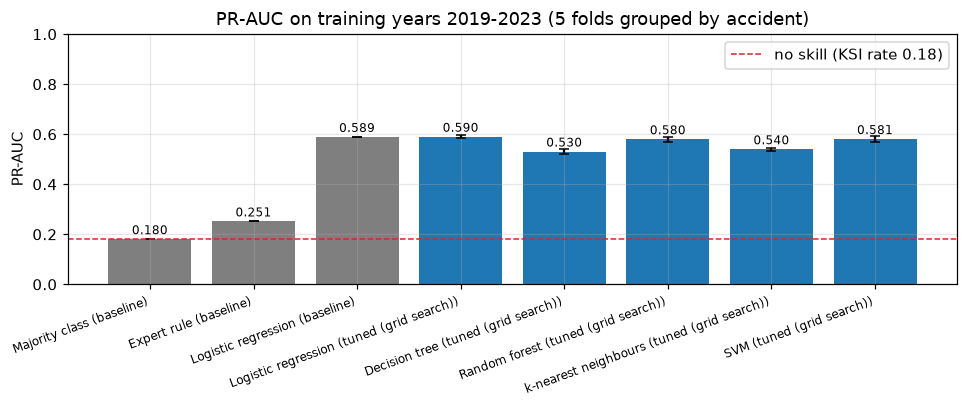

In [4]:
rows = [{"model": m, "kind": "baseline", "pr_auc": base.loc[m, "pr_auc"]} for m in ["Majority class", "Expert rule", "Logistic regression"]]
rows += [{"model": m, "kind": "tuned (grid search)", "pr_auc": b["cv_pr_auc_mean"], "std": b["cv_pr_auc_std"]} for m, b in best.items()]
show = pd.DataFrame(rows)
display(show.round(4))
fig, ax = plt.subplots(figsize=(9, 3.8))
labels = [f"{m} ({k})" for m, k in zip(show.model, show.kind)]
ax.bar(labels, show.pr_auc, yerr=show["std"].fillna(0), capsize=3,
       color=["tab:gray" if k == "baseline" else "tab:blue" for k in show.kind])
ax.axhline(0.18, color="tab:red", ls="--", lw=1, label="no skill (KSI rate 0.18)")
for i, v in enumerate(show.pr_auc):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=8)
ax.set(title="PR-AUC on training years 2019-2023 (5 folds grouped by accident)", ylabel="PR-AUC", ylim=(0, 1))
plt.xticks(rotation=20, ha="right", fontsize=8); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES_DIR / "m3_model_comparison.png"); plt.show()

## 4. Error analysis of the best model
Best setting (logistic regression, C = 0.1) retrained with out-of-fold predictions on **all** training years (`python -u -m src.models.error_analysis`). Threshold = best F2, chosen on these out-of-fold predictions. Recall = share of KSI people the model flags; precision = share of flagged people who are really KSI. Groups with fewer than 300 KSI people are not shown.

,model,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share,tn,fp,fn,tp
0,Logistic regression {'model__C': 0.1},0.5888,0.8722,0.3959,0.8748,0.7044,0.415,0.3984,358733,149117,13982,97720


,predicted: not KSI,predicted: KSI
true: not KSI,358733,149117
true: KSI,13982,97720


Missed KSI people: 13,982 of 111,702 (12.5%); false alarms: 149,117


,variable,group,people,ksi_people,ksi_rate,recall,precision,missed_ksi,false_alarms
4,road_user,Heavy goods vehicle,14074,925,0.0657,0.5989,0.2888,371,1364
9,road_user,Van,38198,2881,0.0754,0.7112,0.3254,832,4247
3,road_user,E-scooter / personal device,8907,1464,0.1644,0.7623,0.2700,348,3017
1,road_user,Car,358380,44711,0.1248,0.8198,0.3646,8055,63873
7,road_user,Other / unknown,10130,1901,0.1877,0.8369,0.3593,310,2837
2,road_user,E-bike,2607,738,0.2831,0.9079,0.4265,68,901
0,road_user,Bicycle,26158,7285,0.2785,0.9159,0.4186,613,9266
5,road_user,Moped <50cc,35043,10305,0.2941,0.9274,0.4008,748,14285
8,road_user,Pedestrian,48109,15810,0.3286,0.9335,0.3941,1052,22687
6,road_user,Motorcycle >50cc,69870,25465,0.3645,0.9432,0.4778,1446,26246


,variable,group,people,ksi_people,ksi_rate,recall,precision,missed_ksi,false_alarms
11,agg,2,382737,50248,0.1313,0.8262,0.3559,8732,75129
10,agg,1,236815,61454,0.2595,0.9146,0.4317,5250,73988


,variable,group,people,ksi_people,ksi_rate,recall,precision,missed_ksi,false_alarms
16,lum,5,95385,13250,0.1389,0.8030,0.3421,2610,20461
12,lum,1,415932,71090,0.1709,0.8725,0.3942,9066,95299
15,lum,4,5731,1167,0.2036,0.8860,0.4056,133,1515
13,lum,2,39799,8103,0.2036,0.8930,0.4018,867,10774
14,lum,3,62693,18090,0.2885,0.9278,0.4435,1306,21061


,variable,group,people,ksi_people,ksi_rate,recall,precision,missed_ksi,false_alarms
17,catr,1,70926,7238,0.1021,0.7014,0.3040,2161,11626
20,catr,4,248547,29868,0.1202,0.8078,0.3378,5741,47300
22,catr,7,19478,3193,0.1639,0.8490,0.3708,482,4600
18,catr,2,44447,8913,0.2005,0.8824,0.4084,1048,11394
19,catr,3,227742,60670,0.2664,0.9271,0.4388,4425,71943
23,catr,9,3583,826,0.2305,0.9310,0.4340,57,1003
21,catr,6,4189,813,0.1941,0.9373,0.4201,51,1052


,variable,group,people,ksi_people,ksi_rate,recall,precision,missed_ksi,false_alarms
26,age_band,25-44,225440,33069,0.1467,0.8462,0.3765,5085,46337
24,age_band,0-17,54589,11169,0.2046,0.8494,0.3404,1682,18380
25,age_band,18-24,116024,21203,0.1827,0.8495,0.3799,3191,29400
27,age_band,45-64,148334,27055,0.1824,0.8992,0.4048,2728,35767
28,age_band,65-74,36480,9401,0.2577,0.9325,0.4515,635,10649
29,age_band,75+,29392,9690,0.3297,0.9364,0.5184,616,8431


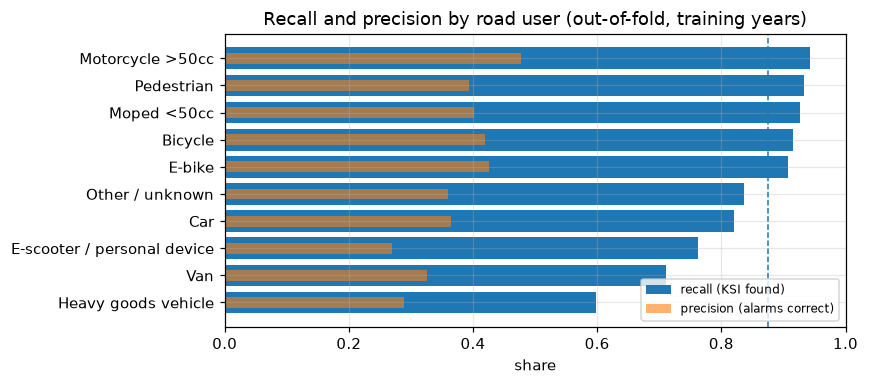

In [5]:
ov = pd.read_csv(RESULTS_DIR / "error_overall.csv")
display(ov)
tn, fp, fn, tp = ov.loc[0, ["tn", "fp", "fn", "tp"]]
display(pd.DataFrame([[tn, fp], [fn, tp]], index=["true: not KSI", "true: KSI"], columns=["predicted: not KSI", "predicted: KSI"]))
print(f"Missed KSI people: {fn:,} of {fn + tp:,} ({fn / (fn + tp):.1%}); false alarms: {fp:,}")
eg = pd.read_csv(RESULTS_DIR / "error_by_group.csv")
for v in eg.variable.unique():
    display(eg[eg.variable == v].sort_values("recall"))
ru = eg[eg.variable == "road_user"].sort_values("recall")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(ru.group, ru.recall, color="tab:blue", label="recall (KSI found)")
ax.barh(ru.group, ru.precision, color="tab:orange", alpha=0.6, height=0.4, label="precision (alarms correct)")
ax.axvline(ov.loc[0, "recall"], color="tab:blue", ls="--", lw=1)
ax.set(title="Recall and precision by road user (out-of-fold, training years)", xlabel="share", xlim=(0, 1))
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "m3_error_by_road_user.png"); plt.show()

## 5. Findings and limits
- **Best model so far: tuned logistic regression**, CV PR-AUC 0.590 ± 0.007 (C = 0.1), with train 0.599: almost no overfitting, and C barely matters (0.588-0.590).
- **SVM (rbf, C = 1) 0.581 and random forest 0.580** come close but memorise the training folds (train 0.80 and 1.00). They were tuned on 10k and 30k people only, so they may gain from more data: to test in Week 4.
- **kNN 0.540**: distances over 394 one-hot columns carry little information (curse of dimensionality).
- **Decision tree 0.530**: the bias-variance plot shows the LAB 6 trap. With leaf 1, depth None gives train 1.000 but validation 0.296 (pure overfitting); with leaf 100 the tree stays at 0.53. Depth 4 underfits (0.41 on both).
- **Limits:** different sample sizes per model (100k / 30k / 20k / 10k) because trees get a sparse one-hot matrix and kNN/SVM scale badly; scores from smaller samples are slightly pessimistic. No confidence intervals yet (bootstrap, M4). Test years 2024-2025 not used.